In [1]:
import pandas as pd
import seaborn as sns
from ast import literal_eval
from datasets import load_dataset
import matplotlib.pyplot as plt


dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].fillna('[]')
df['job_skills'] = df['job_skills'].apply(literal_eval)

c:\Users\Windows 11\miniconda3\envs\python_project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df_US_DE = df[(df['job_title_short'] == 'Data Engineer') & (df['job_country'] == 'United States')]

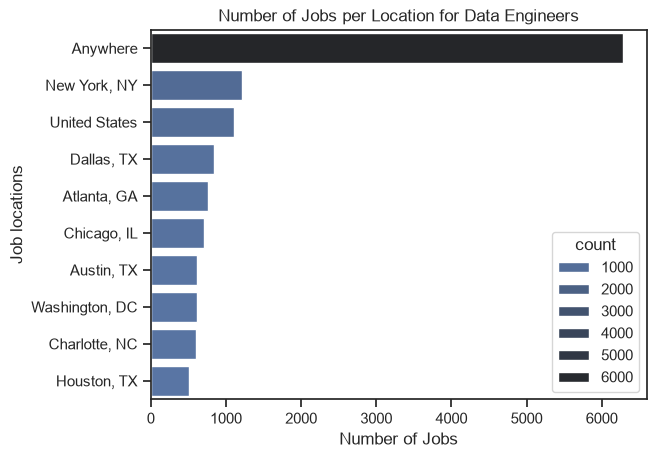

In [4]:
df_plot = df_US_DE['job_location'].value_counts().head(10).to_frame()
sns.set_theme(style='ticks')
sns.barplot(data=df_plot,
             x='count',
               y='job_location',
                 hue='count',
                   palette='dark:b_r')

plt.title('Number of Jobs per Location for Data Engineers')
plt.xlabel('Number of Jobs')
plt.ylabel('Job locations')
plt.show()




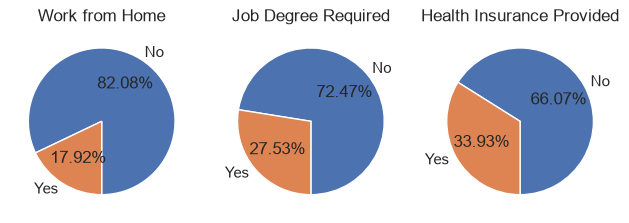

In [5]:
fig, ax = plt.subplots(1, 3)
dict_column = {
    'job_work_from_home' : 'Work from Home',
    'job_no_degree_mention' : 'Job Degree Required',
    'job_health_insurance' : 'Health Insurance Provided'
    }

for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df_US_DE[column].value_counts(), autopct='%1.2f%%', startangle=270, labels=['No', 'Yes'])
    ax[i].set_title(title)


fig.tight_layout()
plt.show()


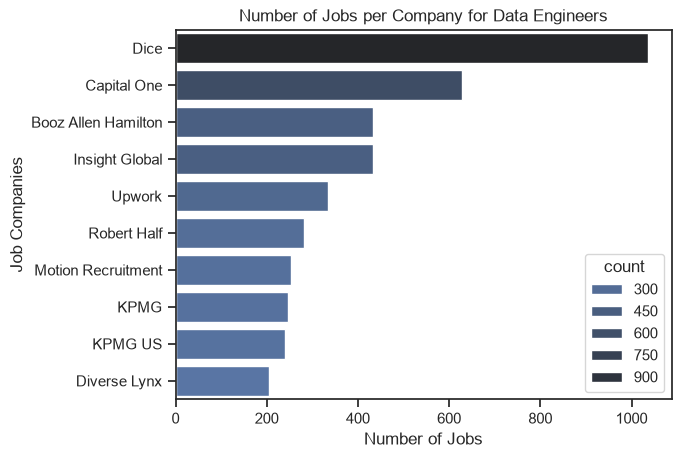

In [7]:
df_plot = df_US_DE['company_name'].value_counts().head(10).to_frame()
sns.set_theme(style='ticks')
sns.barplot(data=df_plot,
             x='count',
               y='company_name',
                 hue='count',
                   palette='dark:b_r')

plt.title('Number of Jobs per Company for Data Engineers')
plt.xlabel('Number of Jobs')
plt.ylabel('Job Companies')
plt.show()


